## Common setup

In [6]:
import random
import itertools
import matplotlib.pyplot as plt

random.seed(42)

def order_crossover(parent1, parent2):
    start, end = sorted(random.sample(range(len(parent1)), 2))
    child = [None] * len(parent1)
    child[start:end + 1] = parent1[start:end + 1]
    remaining = [gene for gene in parent2[end + 1:] + parent2[:end + 1] if gene not in child]
    positions = list(range(end + 1, len(child))) + list(range(end + 1))
    for position, gene in zip((p for p in positions if child[p] is None), remaining):
        child[position] = gene
    return child

def show_board(chromosome, title):
    board = [[(row + col) % 2 for col in range(8)] for row in range(8)]
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(board, cmap='binary', vmin=0, vmax=1)
    for col, row in enumerate(chromosome):
        ax.text(col, row - 1, 'Q', ha='center', va='center', fontsize=22, color='red')
    ax.set_xticks(range(8), range(1, 9))
    ax.set_yticks(range(8), range(1, 9))
    ax.set_xlabel('Column')
    ax.set_ylabel('Row')
    ax.set_title(title)
    plt.show()

### Task 1: Maximize the number of 1s

In [ ]:
CHROMOSOME_LENGTH = 8
POPULATION_SIZE = 10
CROSSOVER_RATE = 0.8
MUTATION_RATE = 0.02
MAX_GENERATIONS = 50

def create_chromosome():
    return [random.randint(0, 1) for _ in range(CHROMOSOME_LENGTH)]

def fitness(chromosome):
    return sum(chromosome)

def tournament_selection(population):
    return max(random.sample(population, 3), key=fitness)

def crossover(parent1, parent2):
    if random.random() >= CROSSOVER_RATE:
        return parent1[:], parent2[:]
    point = random.randrange(1, CHROMOSOME_LENGTH)
    return parent1[:point] + parent2[point:], parent2[:point] + parent1[point:]

def mutate(chromosome):
    return [1 - bit if random.random() < MUTATION_RATE else bit for bit in chromosome]

def run_ga():
    population = [create_chromosome() for _ in range(POPULATION_SIZE)]
    history = []
    best = max(population, key=fitness)[:]
    for generation in range(1, MAX_GENERATIONS + 1):
        current = max(population, key=fitness)
        if fitness(current) > fitness(best):
            best = current[:]
        history.append(fitness(best))
        if fitness(best) == CHROMOSOME_LENGTH:
            break
        next_population = [best[:]]
        while len(next_population) < POPULATION_SIZE:
            child1, child2 = crossover(tournament_selection(population), tournament_selection(population))
            next_population.extend([mutate(child1), mutate(child2)])
        population = next_population[:POPULATION_SIZE]
    return best, fitness(best), history

best, score, history = run_ga()
print('Best chromosome:', best)
print('Best fitness:', score)
print('Best fitness by generation:', history)

Best chromosome: [1, 1, 1, 1, 1, 1, 1, 1]
Best fitness: 8
Best fitness by generation: [5, 6, 6, 6, 7, 7, 7, 7, 7, 7, 7, 8]


## Task 2: Optimize f(x)=x^2

In [8]:
CHROMOSOME_LENGTH = 5
POPULATION_SIZE = 10
MAX_GENERATIONS = 50
CROSSOVER_RATE = 0.8
MUTATION_RATE = 0.02

def decode(chromosome):
    return int(''.join(map(str, chromosome)), 2)

def fitness(chromosome):
    return decode(chromosome) ** 2

def roulette_selection(population):
    scores = [fitness(chromosome) for chromosome in population]
    return random.choices(population, weights=scores, k=1)[0] if sum(scores) else random.choice(population)

def crossover(parent1, parent2):
    if random.random() >= CROSSOVER_RATE:
        return parent1[:], parent2[:]
    point = random.randrange(1, CHROMOSOME_LENGTH)
    return parent1[:point] + parent2[point:], parent2[:point] + parent1[point:]

def mutate(chromosome):
    return [1 - bit if random.random() < MUTATION_RATE else bit for bit in chromosome]

def run_ga():
    population = [[random.randint(0, 1) for _ in range(CHROMOSOME_LENGTH)] for _ in range(POPULATION_SIZE)]
    best = max(population, key=fitness)[:]
    history = []
    for _ in range(MAX_GENERATIONS):
        current = max(population, key=fitness)
        if fitness(current) > fitness(best):
            best = current[:]
        history.append((decode(best), fitness(best)))
        next_population = [best[:]]
        while len(next_population) < POPULATION_SIZE:
            child1, child2 = crossover(roulette_selection(population), roulette_selection(population))
            next_population.extend([mutate(child1), mutate(child2)])
        population = next_population[:POPULATION_SIZE]
    return best, history

best, history = run_ga()
print('Best x and fitness by generation:', history)
print('Final best chromosome:', best)
print('Final best x:', decode(best))
print('Final best fitness:', fitness(best))

Best x and fitness by generation: [(30, 900), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961), (31, 961)]
Final best chromosome: [1, 1, 1, 1, 1]
Final best x: 31
Final best fitness: 961


### Task 3: Travelling Salesperson Problem (TSP)

Best route: K → M → I → L → Q → K
Total distance: 16
Best distance by generation: [16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16]


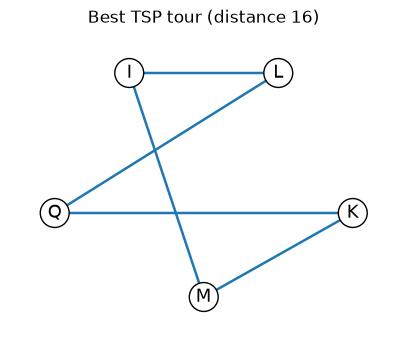

In [9]:
CITIES = ['I', 'L', 'K', 'M', 'Q']
POPULATION_SIZE = 10
MAX_GENERATIONS = 50
DISTANCE = {
    'I': {'I': 0, 'L': 4, 'K': 7, 'M': 3, 'Q': 6},
    'L': {'I': 4, 'L': 0, 'K': 5, 'M': 6, 'Q': 2},
    'K': {'I': 7, 'L': 5, 'K': 0, 'M': 4, 'Q': 3},
    'M': {'I': 3, 'L': 6, 'K': 4, 'M': 0, 'Q': 5},
    'Q': {'I': 6, 'L': 2, 'K': 3, 'M': 5, 'Q': 0},
}

def create_chromosome():
    return random.sample(CITIES, len(CITIES))

def tour_distance(route):
    return sum(DISTANCE[route[i]][route[(i + 1) % len(route)]] for i in range(len(route)))

def fitness(route):
    return 1 / tour_distance(route)

def tournament_selection(population):
    return max(random.sample(population, 3), key=fitness)

def swap_mutation(route):
    route = route[:]
    if random.random() < 0.2:
        i, j = random.sample(range(len(route)), 2)
        route[i], route[j] = route[j], route[i]
    assert sorted(route) == sorted(CITIES)
    return route

def run_ga():
    population = [create_chromosome() for _ in range(POPULATION_SIZE)]
    best = min(population, key=tour_distance)[:]
    history = []
    for _ in range(MAX_GENERATIONS):
        current = min(population, key=tour_distance)
        if tour_distance(current) < tour_distance(best):
            best = current[:]
        history.append(tour_distance(best))
        next_population = [best[:]]
        while len(next_population) < POPULATION_SIZE:
            child = order_crossover(tournament_selection(population), tournament_selection(population))
            assert sorted(child) == sorted(CITIES)
            next_population.append(swap_mutation(child))
        population = next_population
    return best, tour_distance(best), history

best_route, best_distance, history = run_ga()
print('Best route:', ' → '.join(best_route + [best_route[0]]))
print('Total distance:', best_distance)
print('Best distance by generation:', history)

positions = {city: (random_x, random_y) for city, random_x, random_y in [
    ('I', 0, 1), ('L', 1, 1), ('K', 1.5, 0), ('M', 0.5, -0.6), ('Q', -0.5, 0)]}
fig, ax = plt.subplots(figsize=(5, 4))
for start, end in zip(best_route, best_route[1:] + best_route[:1]):
    ax.annotate('', xy=positions[end], xytext=positions[start],
                arrowprops={'arrowstyle': '->', 'lw': 1.8, 'color': 'tab:blue'})
for city, (x, y) in positions.items():
    ax.text(x, y, city, ha='center', va='center', fontsize=13,
            bbox={'boxstyle': 'circle', 'facecolor': 'white', 'edgecolor': 'black'})
ax.set_title(f'Best TSP tour (distance {best_distance})')
ax.set_xlim(-0.8, 1.8)
ax.set_ylim(-0.9, 1.3)
ax.axis('off')
plt.show()

### Task 4: 0/1 Knapsack

In [5]:
WEIGHTS = [2, 3, 4, 5]
VALUES = [3, 4, 5, 8]
CAPACITY = 8
POPULATION_SIZE = 10
MAX_GENERATIONS = 10

def create_chromosome():
    return [random.randint(0, 1) for _ in WEIGHTS]

def total_weight(chromosome):
    return sum(bit * weight for bit, weight in zip(chromosome, WEIGHTS))

def total_value(chromosome):
    return sum(bit * value for bit, value in zip(chromosome, VALUES))

def fitness(chromosome):
    return total_value(chromosome) if total_weight(chromosome) <= CAPACITY else 0

def roulette_selection(population):
    scores = [fitness(chromosome) for chromosome in population]
    return random.choices(population, weights=scores, k=1)[0] if sum(scores) else random.choice(population)

def crossover(parent1, parent2):
    point = random.randrange(1, len(WEIGHTS))
    return parent1[:point] + parent2[point:], parent2[:point] + parent1[point:]

def mutate(chromosome):
    chromosome = chromosome[:]
    point = random.randrange(len(chromosome))
    chromosome[point] = 1 - chromosome[point]
    return chromosome

def run_ga():
    population = [create_chromosome() for _ in range(POPULATION_SIZE)]
    best = None
    history = []
    for _ in range(MAX_GENERATIONS):
        if all(fitness(chromosome) == 0 for chromosome in population):
            feasible_seed = create_chromosome()
            while total_weight(feasible_seed) > CAPACITY:
                feasible_seed = create_chromosome()
            population[0] = feasible_seed
        feasible = [chromosome for chromosome in population if total_weight(chromosome) <= CAPACITY]
        if feasible:
            current = max(feasible, key=total_value)
            if best is None or total_value(current) > total_value(best):
                best = current[:]
        history.append((best[:], total_weight(best), total_value(best)) if best else None)
        next_population = [best[:]] if best else []
        while len(next_population) < POPULATION_SIZE:
            child1, child2 = crossover(roulette_selection(population), roulette_selection(population))
            next_population.extend([mutate(child1), mutate(child2)])
        population = next_population[:POPULATION_SIZE]
    return best, history

best, history = run_ga()
for generation, result in enumerate(history, 1):
    print(f'Generation {generation}: chromosome={result[0]}, weight={result[1]}, value={result[2]}' if result else f'Generation {generation}: no feasible solution yet')
print('Best chromosome:', best)
print('Total weight:', total_weight(best))
print('Total value:', total_value(best))

Generation 1: chromosome=[0, 1, 1, 0], weight=7, value=9
Generation 2: chromosome=[0, 1, 1, 0], weight=7, value=9
Generation 3: chromosome=[0, 1, 0, 1], weight=8, value=12
Generation 4: chromosome=[0, 1, 0, 1], weight=8, value=12
Generation 5: chromosome=[0, 1, 0, 1], weight=8, value=12
Generation 6: chromosome=[0, 1, 0, 1], weight=8, value=12
Generation 7: chromosome=[0, 1, 0, 1], weight=8, value=12
Generation 8: chromosome=[0, 1, 0, 1], weight=8, value=12
Generation 9: chromosome=[0, 1, 0, 1], weight=8, value=12
Generation 10: chromosome=[0, 1, 0, 1], weight=8, value=12
Best chromosome: [0, 1, 0, 1]
Total weight: 8
Total value: 12
